## Step 4 - Final comparison of the 3 tuned models

In [1]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay
)
from lightgbm import LGBMClassifier

In [2]:
from features import build_full_pipeline, load_data

warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [3]:
X_dev, y_dev, X_test, y_test = load_data()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_names = ["logistic_regression", "random_forest", "lightgbm"]

default_models = {
    "logistic_regression": LogisticRegression(max_iter=1000),
    "random_forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "lightgbm": LGBMClassifier(random_state=42, verbose=-1),
}

In [4]:
tuned_pipelines = {}
for name in model_names:
    tuned_pipelines[name] = joblib.load("models/best_" + name + ".pkl")


def best_f1_threshold(y_true, y_proba):
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-10)
    best = np.argmax(f1[:-1])
    return thresholds[best]

In [5]:
# 1. CV on the dev set: default vs tuned + choice of the threshold
cv_rows = []
thresholds = {}
for name in model_names:
    print("CV for", name, "...")
    proba_default = cross_val_predict(build_full_pipeline(default_models[name]), X_dev, y_dev,
                                      cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    # cross_val_predict makes a copy of the pipeline and refits it in each fold
    proba_tuned = cross_val_predict(tuned_pipelines[name], X_dev, y_dev,
                                    cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    thresholds[name] = best_f1_threshold(y_dev, proba_tuned)

    cv_rows.append({
        "model": name,
        "cv_pr_auc_default": average_precision_score(y_dev, proba_default),
        "cv_pr_auc_tuned": average_precision_score(y_dev, proba_tuned),
        "cv_roc_auc_default": roc_auc_score(y_dev, proba_default),
        "cv_roc_auc_tuned": roc_auc_score(y_dev, proba_tuned),
        "threshold_from_cv": thresholds[name],
    })

CV for logistic_regression ...


CV for random_forest ...


CV for lightgbm ...


In [6]:
cv_df = pd.DataFrame(cv_rows)
print("\n--- DEV SET (5-fold CV) : default vs tuned ---")
print(cv_df.round(4).to_string(index=False))
cv_df.to_csv("results/cv_default_vs_tuned.csv", index=False)


--- DEV SET (5-fold CV) : default vs tuned ---
              model  cv_pr_auc_default  cv_pr_auc_tuned  cv_roc_auc_default  cv_roc_auc_tuned  threshold_from_cv
logistic_regression             0.4013           0.4022              0.7633            0.7641             0.1959
      random_forest             0.4116           0.4459              0.7790            0.7955             0.2140
           lightgbm             0.4442           0.4543              0.7969            0.8000             0.3756


In [7]:
# 2. evaluation on the test set (only once)
test_rows = []
test_probas = {}
for name in model_names:
    proba = tuned_pipelines[name].predict_proba(X_test)[:, 1]
    test_probas[name] = proba
    y_pred = (proba >= thresholds[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    test_rows.append({
        "model": name,
        "threshold": thresholds[name],
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "brier": brier_score_loss(y_test, proba),
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })

In [8]:
test_df = pd.DataFrame(test_rows)
print("\n--- TEST SET (untouched until now) ---")
print(test_df.round(4).to_string(index=False))
test_df.to_csv("results/test_results.csv", index=False)


--- TEST SET (untouched until now) ---
              model  threshold  roc_auc  pr_auc  brier  accuracy  precision  recall     f1  TP  FP  FN   TN
logistic_regression     0.1959   0.7731  0.4120 0.0855    0.8724     0.4542  0.4499 0.4520 476 572 582 7413
      random_forest     0.2140   0.8035  0.4610 0.0809    0.8717     0.4579  0.5246 0.4890 555 657 503 7328
           lightgbm     0.3756   0.8093  0.4717 0.0902    0.8713     0.4581  0.5473 0.4987 579 685 479 7300


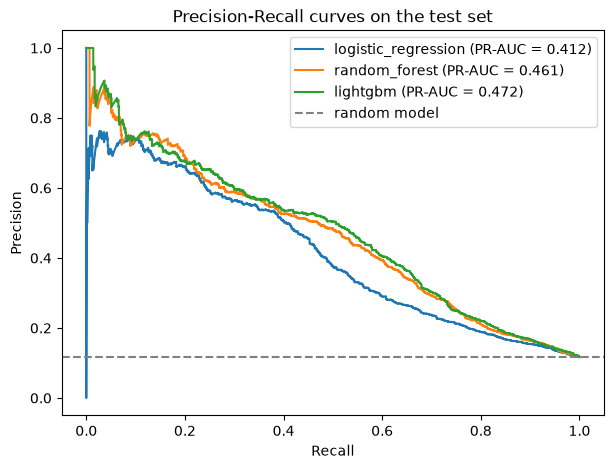

In [9]:
# 3. plots: PR curves, ROC curves, confusion matrices
plt.figure(figsize=(7, 5))
for name in model_names:
    precision, recall, _ = precision_recall_curve(y_test, test_probas[name])
    plt.plot(recall, precision, label=name + " (PR-AUC = " + str(round(average_precision_score(y_test, test_probas[name]), 3)) + ")")
plt.axhline(y_test.mean(), color="grey", linestyle="--", label="random model")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves on the test set")
plt.legend()
plt.savefig("plots/test_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

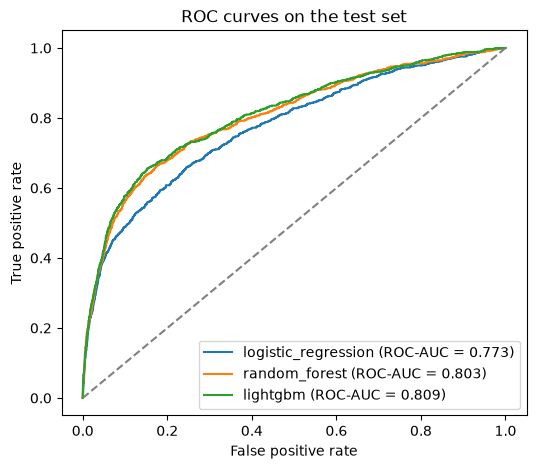

In [10]:
plt.figure(figsize=(6, 5))
for name in model_names:
    fpr, tpr, _ = roc_curve(y_test, test_probas[name])
    plt.plot(fpr, tpr, label=name + " (ROC-AUC = " + str(round(roc_auc_score(y_test, test_probas[name]), 3)) + ")")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend()
plt.savefig("plots/test_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

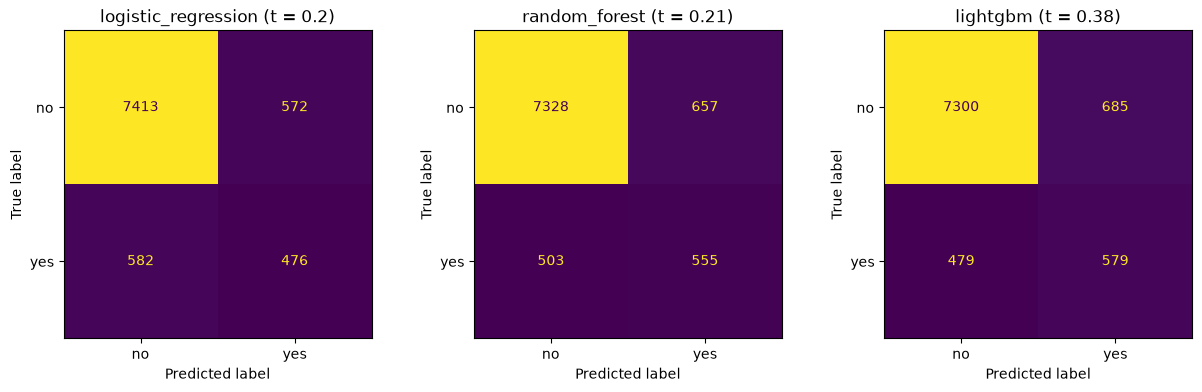

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i in range(3):
    name = model_names[i]
    y_pred = (test_probas[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["no", "yes"]).plot(ax=axes[i], colorbar=False)
    axes[i].set_title(name + " (t = " + str(round(thresholds[name], 2)) + ")")
plt.savefig("plots/test_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# 4. final model = best CV PR-AUC (we don't choose with the test set)
best_name = cv_df.sort_values("cv_pr_auc_tuned", ascending=False)["model"].iloc[0]
print("\nFinal model (best CV PR-AUC):", best_name, "- threshold:", round(thresholds[best_name], 3))
with open("results/final_choice.json", "w") as f:
    json.dump({"model": best_name, "threshold": float(thresholds[best_name])}, f, indent=4)


Final model (best CV PR-AUC): lightgbm - threshold: 0.376


In [13]:
# 5. log the test evaluation in MLflow too
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("bank_marketing_final_evaluation")
for row in test_rows:
    with mlflow.start_run(run_name=row["model"] + "_test"):
        mlflow.log_param("model", row["model"])
        mlflow.log_param("threshold", row["threshold"])
        for metric in ["roc_auc", "pr_auc", "brier", "accuracy", "precision", "recall", "f1"]:
            mlflow.log_metric("test_" + metric, row[metric])
        mlflow.log_artifact("plots/test_pr_curves.png")
        mlflow.log_artifact("plots/test_confusion_matrices.png")
print("Test results logged in MLflow (experiment bank_marketing_final_evaluation)")

2026/10/15 16:03:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/15 16:03:11 INFO mlflow.store.db.utils: Updating database tables


2026/10/15 16:03:12 INFO mlflow.tracking.fluent: Experiment with name 'bank_marketing_final_evaluation' does not exist. Creating a new experiment.


Test results logged in MLflow (experiment bank_marketing_final_evaluation)
